Member: Seunghyun Park, Hyunwoo Sun

Data URL: https://archive.ics.uci.edu/dataset/9/auto+mpg

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Use raw string r'\s+' to prevent syntax warnings and read data on whitespace.
df = pd.read_csv('auto-mpg.data', sep=r'\s+', names=['mpg', 'cylinders', 'displacement', 'horsepower',
           'weight', 'acceleration', 'model year', 'origin', 'car name'], na_values='?')

df = df.dropna()

In [16]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [17]:
from sklearn.preprocessing import StandardScaler

features = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration']

#separating out the features
x = df.loc[:, features].values

#separating out the target
y = df.loc[:, ['origin']].values

#Standardizing the features
x = StandardScaler().fit_transform(x)

In [18]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
principalComponents=pca.fit_transform(x)
principalDf=pd.DataFrame(data=principalComponents, columns=['principal comp 1', 'principal comp 2'])

In [19]:
principalDf.head()

,principal comp 1,principal comp 2
0,2.325970,-0.572082
1,3.206057,-0.682741
2,2.669984,-0.994013
3,2.605465,-0.622770
4,2.599901,-1.093593


In [20]:
finalDf=pd.concat([principalDf, df[['origin']]], axis=1)
finalDf.head()

,principal comp 1,principal comp 2,origin
0,2.325970,-0.572082,1.0
1,3.206057,-0.682741,1.0
2,2.669984,-0.994013,1.0
3,2.605465,-0.622770,1.0
4,2.599901,-1.093593,1.0


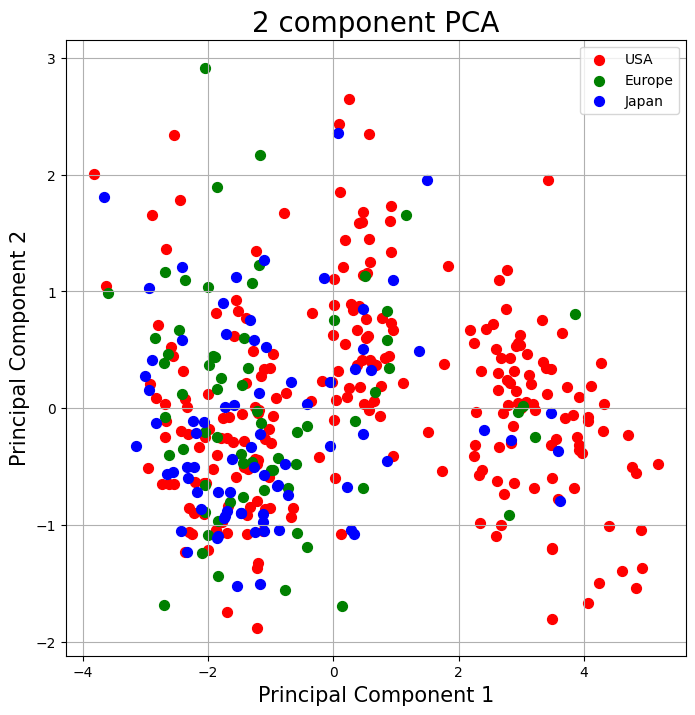

In [21]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize = (8,8))
ax = fig.add_subplot(1,1,1)
ax.set_xlabel('Principal Component 1', fontsize = 15)
ax.set_ylabel('Principal Component 2', fontsize = 15)
ax.set_title('2 component PCA', fontsize = 20)

targets = [1, 2, 3]
colors = ['r', 'g', 'b']
for target, color in zip(targets,colors):
    indicesToKeep = finalDf['origin'] == target
    ax.scatter(finalDf.loc[indicesToKeep, 'principal comp 1']
               , finalDf.loc[indicesToKeep, 'principal comp 2']
               , c = color
               , s = 50)
ax.legend(['USA', 'Europe', 'Japan'])
ax.grid()

In [22]:
pca.explained_variance_ratio_

array([0.79804436, 0.12143852])

The original six features were reduced to two principal components using PCA. The first principal component explains 80% of the total variance, and the second explains 12%. Together, they explain 92% of the total variance. This means that the two principal components preserve most of the information in the original dataset.